# JS08 - Lab Assignment 1: Agglomerative Clustering on CC_Customer_Dataset.csv

In [1]:
from google.colab import drive
drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/ImagesML/'

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv(glob.glob(DATA + 'CC_Customer*')[0])
print(df.shape)
df.head()

Mounted at /content/drive
(660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


## 1. Agglomerative Clustering with All Usable Variables

In [2]:
def col(keyword):
    return [c for c in df.columns if keyword.lower() in c.lower().replace(' ', '_')][0]

c_limit = col('avg_credit')
c_cards = col('total_credit')

id_cols = [c for c in df.columns if c.lower().replace(' ', '_') in ('sl_no', 'customer_key', 'id', 'customerid')]
features = [c for c in df.select_dtypes(include=np.number).columns if c not in id_cols]
print('Usable variables:', features)

X = StandardScaler().fit_transform(df[features])

results = {}
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    results[k] = (silhouette_score(X, labels), davies_bouldin_score(X, labels))
    print(f'k={k} | Silhouette={results[k][0]:.4f} | DBI={results[k][1]:.4f}')

best_k = max(results, key=lambda k: results[k][0])
print('Best number of clusters (highest silhouette):', best_k)

hc = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
y_hc = hc.fit_predict(X)

Usable variables: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
k=2 | Silhouette=0.4177 | DBI=0.9326
k=3 | Silhouette=0.5148 | DBI=0.6810
k=4 | Silhouette=0.3481 | DBI=1.1493
k=5 | Silhouette=0.2569 | DBI=1.3851
k=6 | Silhouette=0.2268 | DBI=1.4109
k=7 | Silhouette=0.2163 | DBI=1.4394
k=8 | Silhouette=0.2187 | DBI=1.4489
Best number of clusters (highest silhouette): 3


## 2. Scatterplot of the Clusters (Avg_Credit_Limit vs Total_credit_card)

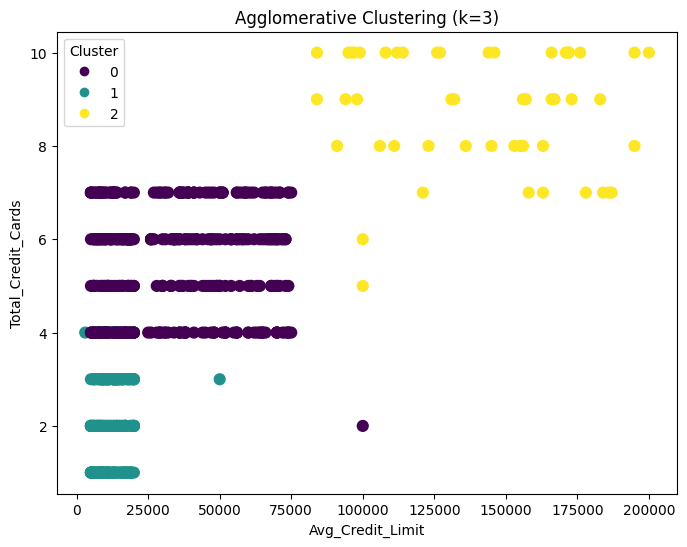

In [3]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df[c_limit], df[c_cards], c=y_hc, cmap='viridis', s=60)
plt.xlabel(c_limit)
plt.ylabel(c_cards)
plt.title(f'Agglomerative Clustering (k={best_k})')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.show()

## 3. Silhouette Score and Davies-Bouldin Index

In [4]:
print('Silhouette Score:', silhouette_score(X, y_hc))
print('Davies-Bouldin Index:', davies_bouldin_score(X, y_hc))

Silhouette Score: 0.5147639589977819
Davies-Bouldin Index: 0.680959518994733
